In [ ]:
import geopandas
import pandas as pd
import mapclassify
from matplotlib import colormaps
import matplotlib.pyplot as plt

Heatmaps of regions accessible from Kreuzberg/Wilmersdorf

List of years to create maps for (1964 later removed)

In [63]:
years = [1951,1961,1964,1967,1976,1984]

Heat map that removes the calculated value for stops accessible within the own district:

(District name needs to be manually changed)

/var/folders/l_/x12p1dds19n9lv81bj_mbs0m0000gn/T/ipykernel_15820/3022331001.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  berlinmap["num_Wilmersdorf"].loc["Wilmersdorf"] = None
/var/folders/l_/x12p1dds19n9lv81bj_mbs0m0000gn/T/ipykernel_15820/3022331001.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  berlinmap["num_Wilmersdorf"].loc["Wilmersdorf"] = None
/var/folders/l_/x12p1dds19n9lv81bj_mbs0m0000gn/T/ipykernel_15820/3022331001.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/use

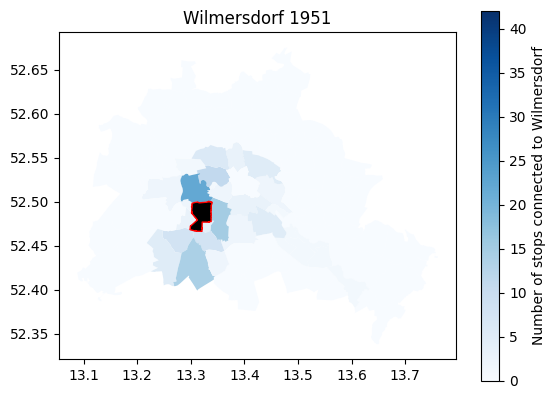

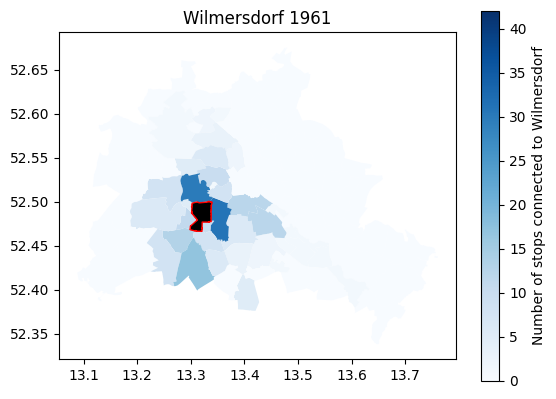

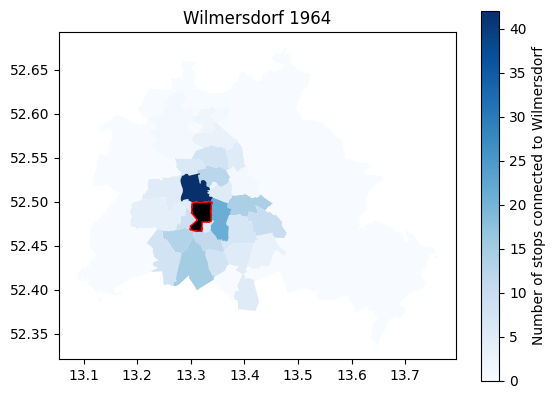

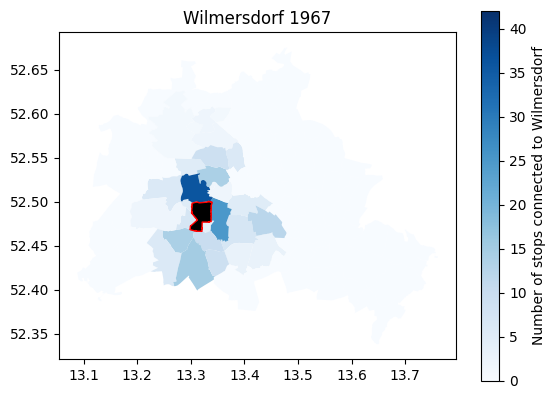

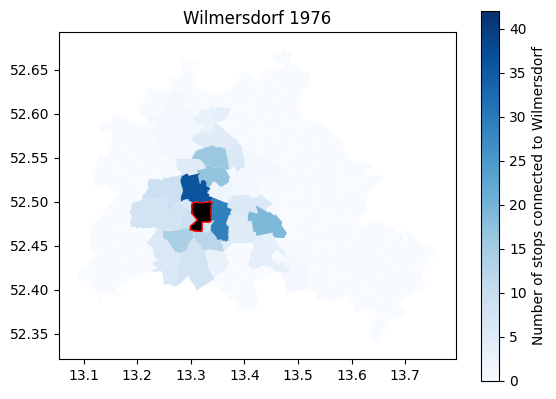

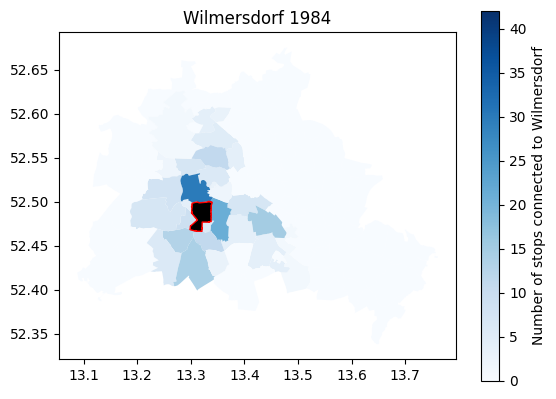

In [ ]:
for year in years:
    berlinmap = geopandas.read_file(f"AnalysisDataset/stations_bydistrict_Wilmersdorf_{year}.json")
    berlinmap = berlinmap.to_crs("EPSG:4326") # gives real-world co-ordinate format for accurate mapping
    berlinmap = berlinmap.set_index("name")
    berlinmap["num_Wilmersdorf"].loc["Wilmersdorf"] = None
    myplot = berlinmap.plot("num_Wilmersdorf", vmax = 42, cmap="Blues",missing_kwds={ # vmax is maximum value of stops in any district across any year
        "color": "black",
        "edgecolor": "red",
        "label": "Wilmersdorf"},legend=True,legend_kwds={"label": "Number of stops connected to Wilmersdorf"})
    myplot.set_title(f"Wilmersdorf {year}")
    myplot.figure.savefig(f"RevisedHeatMaps/removedown_Wilmersdorf {year}")

Heat map that includes the own district's accessible stops

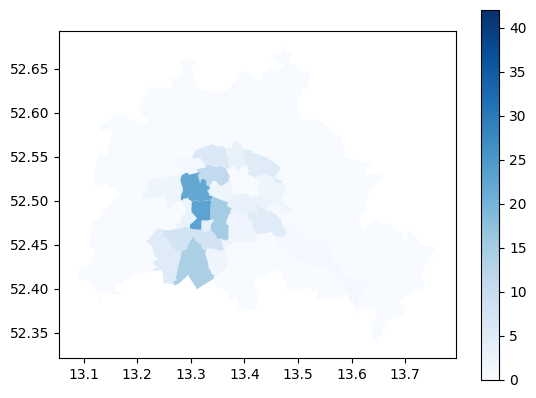

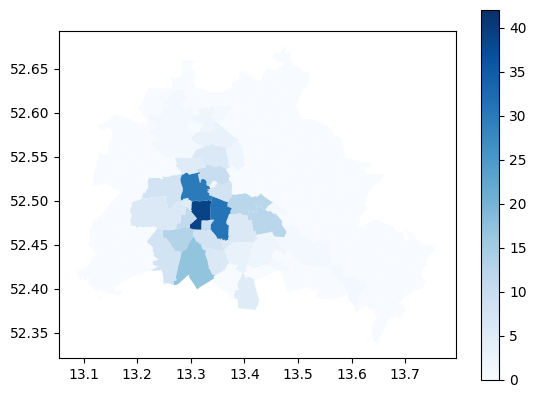

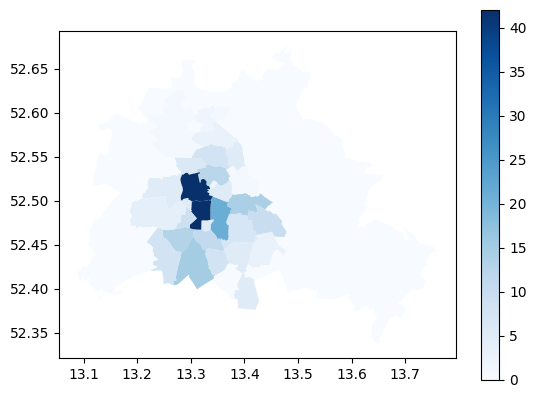

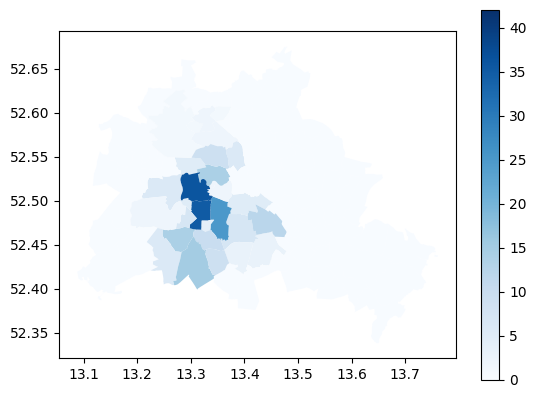

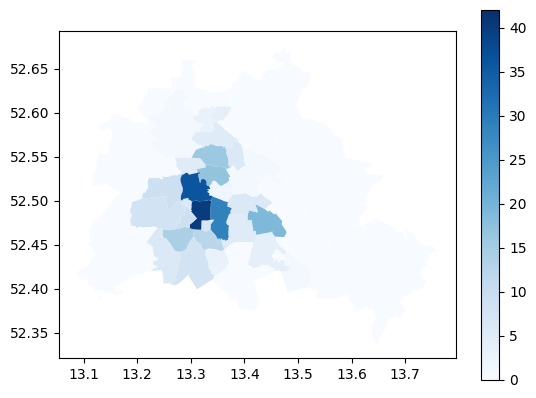

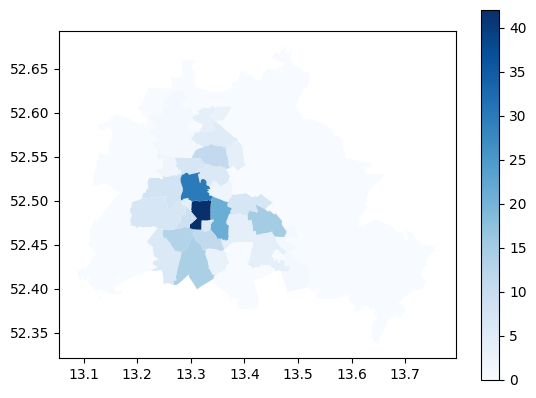

In [68]:
for year in years:
    berlinmap = geopandas.read_file(f"AnalysisDataset/stations_bydistrict_Wilmersdorf_{year}.json")
    berlinmap = berlinmap.to_crs("EPSG:4326")
    berlinmap = berlinmap.set_index("name")
    berlinmap.plot("num_Wilmersdorf", vmax = 42, cmap="Blues",legend=True).figure.savefig(f"RevisedHeatMaps/includeown_Wilmersdorf{year}")